# Airline Reviews Analysis Using Natural Language Processing

## Project Purpose

Airlines receive large volumes of passenger reviews containing detailed information
about customer experiences. Manually reading these reviews can be time-consuming and difficult to organize.

The purpose of this project is to use Natural Language Processing (NLP) to identify specific airline service problems from passenger review text. The analysis focuses on seven service categories: Seat Comfort, Cabin Staff Service, Food & Beverages, Ground Service, Inflight Entertainment, Wi-Fi & Connectivity, and Value for Money.

Passenger service ratings are converted into binary labels representing Problem and No Problem. The review text is cleaned and transformed into numerical features using TF-IDF, and separate Logistic Regression classifiers are developed for each service category using a binary relevance approach.

The models are evaluated using Accuracy, Precision, Recall, F1 Score, Classification Reports, and Confusion Matrices. Important words and phrases are also examined to better understand the language associated with passenger dissatisfaction and positive service experiences

### Research Questions

1. Can passenger review text be used to identify specific airline service problems?
2. How accurately can TF-IDF and Logistic Regression classify the seven service categories?
3. Which airline service categories are easier or more difficult to predict?
4. What words and phrases are most strongly associated with service problems and positive experiences?
5. How does class imbalance affect model performance across the service categories?

The dataset selected for this project is an airline passenger review dataset obtained from Kaggle. 
https://www.kaggle.com/datasets/juhibhojani/airline-reviews/data?select=Airline_review.csv


In [1]:


# Basic libraries

import pandas as pd
# pandas is used to load, clean, and organize the dataset in tables/dataframes

import numpy as np
# numpy is used for numerical operations and handling missing values such as NaN

import matplotlib.pyplot as plt
# matplotlib is used to create graphs and visualizations

import re
# re is used for text cleaning with regular expressions,
# such as removing URLs, punctuation, and unwanted characters

import nltk
# NLTK provides Natural Language Processing tools


# NLP tools

from nltk.corpus import stopwords
# stopwords contains common words such as "the", "is", and "and"
# that may not add much meaning to the analysis

from nltk.stem import WordNetLemmatizer
# lemmatizer reduces words to a simpler/base form
# for example, "cars" may become "car"


# Text visualization

from wordcloud import WordCloud
# WordCloud is used to visually display the most frequent words in reviews


# Machine learning

from sklearn.model_selection import train_test_split
# splits the data into training and testing sets

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
# TfidfVectorizer converts review text into numerical features for modeling
# CountVectorizer counts how frequently words or phrases occur

from sklearn.linear_model import LogisticRegression
# Logistic Regression is the classification model used to predict
# whether a review represents a service problem or no problem


# Model evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# accuracy_score: measures the overall percentage of correct predictions
# precision_score: measures how often predicted problems are actually problems
# recall_score: measures how many actual problems were correctly identified
# f1_score: balances precision and recall
# classification_report: gives detailed performance metrics for each class
# confusion_matrix: shows correct and incorrect predictions
# ConfusionMatrixDisplay: displays the confusion matrix as a graph


# Download NLTK resources

nltk.download('stopwords')
# downloads the list of common English stop words

nltk.download('wordnet')
# downloads the WordNet database needed for lemmatization

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\vinay\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\vinay\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [2]:
#!pip install wordcloud

## Load Data

In [3]:
df = pd.read_csv("Airline_review.csv")

df.head()

,Unnamed: 0,Airline Name,Overall_Rating,Review_Title,Review Date,Verified,Review,Aircraft,Type Of Traveller,Seat Type,Route,Date Flown,Seat Comfort,Cabin Staff Service,Food & Beverages,Ground Service,Inflight Entertainment,Wifi & Connectivity,Value For Money,Recommended
0,0,AB Aviation,9,"""pretty decent airline""",11th November 2019,True,Moroni to Moheli. Turned out to be a pretty ...,NaN,Solo Leisure,Economy Class,Moroni to Moheli,November 2019,4.0,5.0,4.0,4.0,NaN,NaN,3.0,yes
1,1,AB Aviation,1,"""Not a good airline""",25th June 2019,True,Moroni to Anjouan. It is a very small airline...,E120,Solo Leisure,Economy Class,Moroni to Anjouan,June 2019,2.0,2.0,1.0,1.0,NaN,NaN,2.0,no
2,2,AB Aviation,1,"""flight was fortunately short""",25th June 2019,True,Anjouan to Dzaoudzi. A very small airline an...,Embraer E120,Solo Leisure,Economy Class,Anjouan to Dzaoudzi,June 2019,2.0,1.0,1.0,1.0,NaN,NaN,2.0,no
3,3,Adria Airways,1,"""I will never fly again with Adria""",28th September 2019,False,Please do a favor yourself and do not fly wi...,NaN,Solo Leisure,Economy Class,Frankfurt to Pristina,September 2019,1.0,1.0,NaN,1.0,NaN,NaN,1.0,no
4,4,Adria Airways,1,"""it ruined our last days of holidays""",24th September 2019,True,Do not book a flight with this airline! My fr...,NaN,Couple Leisure,Economy Class,Sofia to Amsterdam via Ljubljana,September 2019,1.0,1.0,1.0,1.0,1.0,1.0,1.0,no


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23171 entries, 0 to 23170
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              23171 non-null  int64  
 1   Airline Name            23171 non-null  object 
 2   Overall_Rating          23171 non-null  object 
 3   Review_Title            23171 non-null  object 
 4   Review Date             23171 non-null  object 
 5   Verified                23171 non-null  bool   
 6   Review                  23171 non-null  object 
 7   Aircraft                7129 non-null   object 
 8   Type Of Traveller       19433 non-null  object 
 9   Seat Type               22075 non-null  object 
 10  Route                   19343 non-null  object 
 11  Date Flown              19417 non-null  object 
 12  Seat Comfort            19016 non-null  float64
 13  Cabin Staff Service     18911 non-null  float64
 14  Food & Beverages        14500 non-null

### Data Cleaning

In [5]:

# Remove unnecessary index column
df = df.drop(columns=['Unnamed: 0'])

# Check the new shape
print("Dataset shape after removing index column:", df.shape)

Dataset shape after removing index column: (23171, 19)


In [6]:
# Check for duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 120


In [7]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Check the new shape
print("Dataset shape after removing duplicates:", df.shape)

# Confirm duplicates are removed
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (23051, 19)
Remaining duplicate rows: 0


In [8]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Show only columns that contain missing values
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Missing values by column:")
print(missing_values)

Missing values by column:
Wifi & Connectivity       17133
Aircraft                  15924
Inflight Entertainment    12224
Food & Beverages           8555
Ground Service             4682
Cabin Staff Service        4149
Seat Comfort               4044
Route                      3716
Date Flown                 3642
Type Of Traveller          3627
Seat Type                   989
Value For Money             959
dtype: int64


In [9]:
# Calculate missing-value percentage for each column
missing_percent = (df.isnull().sum() / len(df)) * 100

# Show only columns with missing values
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percent': missing_percent
})

missing_summary = missing_summary[missing_summary['Missing Count'] > 0]
missing_summary = missing_summary.sort_values(
    by='Missing Percent',
    ascending=False
)

print(missing_summary.round(2))

                        Missing Count  Missing Percent
Wifi & Connectivity             17133            74.33
Aircraft                        15924            69.08
Inflight Entertainment          12224            53.03
Food & Beverages                 8555            37.11
Ground Service                   4682            20.31
Cabin Staff Service              4149            18.00
Seat Comfort                     4044            17.54
Route                            3716            16.12
Date Flown                       3642            15.80
Type Of Traveller                3627            15.73
Seat Type                         989             4.29
Value For Money                   959             4.16


For now, I am not filling or deleting these missing service ratings. Missing ratings may mean that a passenger did not use or evaluate that service, so replacing them with an average could create false labels.

In [10]:
# Check essential columns for NLP analysis

print("Missing Review values:", df['Review'].isnull().sum())
print("Missing Overall_Rating values:", df['Overall_Rating'].isnull().sum())

# Check for empty review strings
empty_reviews = df['Review'].astype(str).str.strip().eq('').sum()
print("Empty Review values:", empty_reviews)

# Check unique values of Overall_Rating
print("\nOverall Rating values:")
print(sorted(df['Overall_Rating'].unique()))

Missing Review values: 0
Missing Overall_Rating values: 0
Empty Review values: 0

Overall Rating values:
['1', '2', '3', '4', '5', '6', '7', '8', '9', 'n']


Overall_Rating should be numeric, but there is an unexpected value 'n'. Before replacing or deleting it, we should see how many rows contain it and inspect those records

In [11]:
#Investigate the invalid Overall_Rating value

# Check frequency of each Overall_Rating value
print("Overall Rating value counts:")
print(df['Overall_Rating'].value_counts().sort_index())

# Check rows where Overall_Rating is 'n'
invalid_ratings = df[df['Overall_Rating'] == 'n']

print("\nNumber of rows with invalid rating 'n':", len(invalid_ratings))

# Display a few affected records
display(
    invalid_ratings[
        ['Airline Name', 'Overall_Rating', 'Review_Title', 'Review', 'Recommended']
    ].head(10)
)

Overall Rating value counts:
Overall_Rating
1    11587
2     2294
3     1353
4      853
5      826
6      672
7     1193
8     1756
9     1768
n      749
Name: count, dtype: int64

Number of rows with invalid rating 'n': 749


,Airline Name,Overall_Rating,Review_Title,Review,Recommended
77,Adria Airways,n,Adria Airways customer review,BRU-LJU-BRU. Outward flight on a CRJ200 very n...,no
78,Adria Airways,n,Adria Airways customer review,I often fly with Adria (50 flights per year). ...,no
79,Adria Airways,n,Adria Airways customer review,LGW-LJU-LGW on an older but clean A320. Outwar...,no
80,Adria Airways,n,Adria Airways customer review,Frankfurt-Ljubljana-Munich in business class: ...,no
81,Adria Airways,n,Adria Airways customer review,Zurich-Ljubljana return. About 2 hours+ journe...,no
82,Adria Airways,n,Adria Airways customer review,LGW-LJU return. Outbound was on A320 seated to...,no
83,Adria Airways,n,Adria Airways customer review,LGW-LJU-LGW last week overall impressed with s...,no
84,Adria Airways,n,Adria Airways customer review,DUB-NAP. Was expecting very poor standards of ...,no
85,Adria Airways,n,Adria Airways customer review,Frankfurt to Vienna and was quite satisfied. I...,no
86,Adria Airways,n,Adria Airways customer review,Flew to Ljubljana from Gatwick. Plane was a ne...,no


There are 749 rows with Overall_Rating = 'n'. We should not change those to 10—there is no evidence that n means 10.
Since our project is mainly using the review text to predict service-area problems, we also should not immediately delete 749 otherwise useful reviews.

In [12]:
#Investigate the 'n' records


# Investigate rows where Overall_Rating is 'n'

print("Recommended values for invalid ratings:")
print(invalid_ratings['Recommended'].value_counts(dropna=False))

print("\nReview date range:")
print("Earliest:", invalid_ratings['Review Date'].iloc[-1])
print("Latest:", invalid_ratings['Review Date'].iloc[0])

print("\nMissing service ratings among 'n' records:")
service_columns = [
    'Seat Comfort',
    'Cabin Staff Service',
    'Food & Beverages',
    'Ground Service',
    'Inflight Entertainment',
    'Wifi & Connectivity',
    'Value For Money'
]

print(invalid_ratings[service_columns].isnull().sum())

Recommended values for invalid ratings:
Recommended
no     745
yes      4
Name: count, dtype: int64

Review date range:
Earliest: 6th May 2003
Latest: 4th October 2007

Missing service ratings among 'n' records:
Seat Comfort              572
Cabin Staff Service       572
Food & Beverages          572
Ground Service            749
Inflight Entertainment    573
Wifi & Connectivity       749
Value For Money           433
dtype: int64


In [13]:
# Convert Overall_Rating to numeric
# Invalid values such as 'n' will become NaN

df['Overall_Rating'] = pd.to_numeric(
    df['Overall_Rating'],
    errors='coerce'
)

# Check the result
print("Data type:", df['Overall_Rating'].dtype)
print("Missing Overall_Rating values:", df['Overall_Rating'].isnull().sum())

print("\nOverall Rating value counts:")
print(df['Overall_Rating'].value_counts(dropna=False).sort_index())

Data type: float64
Missing Overall_Rating values: 749

Overall Rating value counts:
Overall_Rating
1.0    11587
2.0     2294
3.0     1353
4.0      853
5.0      826
6.0      672
7.0     1193
8.0     1756
9.0     1768
NaN      749
Name: count, dtype: int64


In [14]:
# Clean and convert Review Date to datetime

df['Review Date'] = (
    df['Review Date']
    .str.replace(r'(\d+)(st|nd|rd|th)', r'\1', regex=True)
)

df['Review Date'] = pd.to_datetime(
    df['Review Date'],
    errors='coerce'
)

# Check results
print("Review Date data type:", df['Review Date'].dtype)
print("Missing/invalid Review Dates:", df['Review Date'].isnull().sum())

print("\nEarliest Review Date:", df['Review Date'].min())
print("Latest Review Date:", df['Review Date'].max())

print("\nSample:")
print(df['Review Date'].head())

Review Date data type: datetime64[ns]
Missing/invalid Review Dates: 0

Earliest Review Date: 2002-01-06 00:00:00
Latest Review Date: 2023-07-27 00:00:00

Sample:
0   2019-11-11
1   2019-06-25
2   2019-06-25
3   2019-09-28
4   2019-09-24
Name: Review Date, dtype: datetime64[ns]


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23051 entries, 0 to 23050
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Airline Name            23051 non-null  object        
 1   Overall_Rating          22302 non-null  float64       
 2   Review_Title            23051 non-null  object        
 3   Review Date             23051 non-null  datetime64[ns]
 4   Verified                23051 non-null  bool          
 5   Review                  23051 non-null  object        
 6   Aircraft                7127 non-null   object        
 7   Type Of Traveller       19424 non-null  object        
 8   Seat Type               22062 non-null  object        
 9   Route                   19335 non-null  object        
 10  Date Flown              19409 non-null  object        
 11  Seat Comfort            19007 non-null  float64       
 12  Cabin Staff Service     18902 non-null  float6

In [16]:
# Check unique values in important categorical columns

categorical_columns = [
    'Verified',
    'Type Of Traveller',
    'Seat Type',
    'Recommended'
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


Verified:
Verified
True     12319
False    10732
Name: count, dtype: int64

Type Of Traveller:
Type Of Traveller
Solo Leisure      7116
Couple Leisure    5262
Family Leisure    4352
NaN               3627
Business          2694
Name: count, dtype: int64

Seat Type:
Seat Type
Economy Class      19133
Business Class      2097
NaN                  989
Premium Economy      646
First Class          186
Name: count, dtype: int64

Recommended:
Recommended
no     15251
yes     7800
Name: count, dtype: int64


categorical columns are already clean. There are no spelling/capitalization inconsistencies to fix.
Verified is already Boolean (True/False). Type Of Traveller and Seat Type have valid categories, and their missing values should remain missing for now rather than being guessed. Recommended contains only yes and no, so we can safely convert it to a binary variable, which will be useful for analysis.

In [17]:
# Convert Recommended from yes/no to 1/0

df['Recommended'] = df['Recommended'].map({
    'yes': 1,
    'no': 0
})

# Check the result
print("Recommended value counts:")
print(df['Recommended'].value_counts())

print("\nRecommended data type:")
print(df['Recommended'].dtype)

Recommended value counts:
Recommended
0    15251
1     7800
Name: count, dtype: int64

Recommended data type:
int64


Before we create the binary service-problem labels, we need to confirm that the service ratings contain only the expected values 1 through 5 plus missing values.

In [18]:

# Create the seven service-problem target columns

df['Seat_Comfort_Problem'] = (
    df['Seat Comfort'].apply(create_problem_label)
)

df['Cabin_Staff_Problem'] = (
    df['Cabin Staff Service'].apply(create_problem_label)
)

df['Food_Beverage_Problem'] = (
    df['Food & Beverages'].apply(create_problem_label)
)

df['Ground_Service_Problem'] = (
    df['Ground Service'].apply(create_problem_label)
)

df['Inflight_Entertainment_Problem'] = (
    df['Inflight Entertainment'].apply(create_problem_label)
)

df['Wifi_Problem'] = (
    df['Wifi & Connectivity'].apply(create_problem_label)
)

df['Value_For_Money_Problem'] = (
    df['Value For Money'].apply(create_problem_label)
)

print("Binary service-problem labels created.")

NameError: name 'create_problem_label' is not defined

In [ ]:
problem_columns = [
    'Seat_Comfort_Problem',
    'Cabin_Staff_Problem',
    'Food_Beverage_Problem',
    'Ground_Service_Problem',
    'Inflight_Entertainment_Problem',
    'Wifi_Problem',
    'Value_For_Money_Problem'
]

for column in problem_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

In [ ]:
# Correlation matrix between service-problem labels

target_corr = df[problem_columns].corr()

display(target_corr.round(2))

In [ ]:
# Visualize correlations between service-problem labels

plt.figure(figsize=(10, 8))

plt.imshow(
    target_corr,
    aspect='auto'
)

plt.colorbar(label='Correlation')

labels = [
    column.replace('_Problem', '').replace('_', ' ')
    for column in problem_columns
]

plt.xticks(
    range(len(labels)),
    labels,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(labels)),
    labels
)

for i in range(len(problem_columns)):
    for j in range(len(problem_columns)):

        value = target_corr.iloc[i, j]

        if not np.isnan(value):
            plt.text(
                j,
                i,
                f'{value:.2f}',
                ha='center',
                va='center'
            )

plt.title(
    'Correlation Between Airline Service-Problem Labels'
)

plt.tight_layout()
plt.show()

In [ ]:
[col for col in df.columns if 'Problem' in col]

In [ ]:
# Examine distribution of values in each service-rating column

for column in service_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False).sort_index())

Six service columns contain 0.0, while Ground Service contains only 1–5.
Before converting 0 to missing, we should see how often it occurs. We should not assume yet that 0 means a terrible rating; it could represent “not rated/not applicable” in this dataset.

Observed rating scale is otherwise 1–5, and 0 appears only in some service columns, we should treat 0 as not rated / unavailable rather than as the worst rating. This is especially important before creating your binary targets.

In [19]:
#Replace service-rating zeros with missing values


# Replace 0 ratings with NaN in service-rating columns
for column in service_columns:
    df[column] = df[column].replace(0, np.nan)

# Verify that no zero ratings remain
print("Remaining zero values:")
for column in service_columns:
    print(column, ":", (df[column] == 0).sum())

# Check updated missing-value counts
print("\nUpdated missing values:")
print(df[service_columns].isnull().sum())

Remaining zero values:
Seat Comfort : 0
Cabin Staff Service : 0
Food & Beverages : 0
Ground Service : 0
Inflight Entertainment : 0
Wifi & Connectivity : 0
Value For Money : 0

Updated missing values:
Seat Comfort               4188
Cabin Staff Service        4279
Food & Beverages           8807
Ground Service             4682
Inflight Entertainment    12745
Wifi & Connectivity       17134
Value For Money            1096
dtype: int64


In [20]:
# Show percentage distribution of ratings 1–5
# Missing values are excluded from the percentage calculation

for column in service_columns:
    print(f"\n{column}:")
    
    percentages = (
        df[column]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )
    
    print(percentages)


Seat Comfort:
Seat Comfort
1.0    33.57
2.0    15.20
3.0    19.17
4.0    17.90
5.0    14.15
Name: proportion, dtype: float64

Cabin Staff Service:
Cabin Staff Service
1.0    31.79
2.0    12.57
3.0    15.16
4.0    15.66
5.0    24.82
Name: proportion, dtype: float64

Food & Beverages:
Food & Beverages
1.0    37.08
2.0    13.81
3.0    17.00
4.0    16.37
5.0    15.73
Name: proportion, dtype: float64

Ground Service:
Ground Service
1.0    51.54
2.0     8.68
3.0     9.80
4.0    12.78
5.0    17.19
Name: proportion, dtype: float64

Inflight Entertainment:
Inflight Entertainment
1.0    46.99
2.0    12.40
3.0    16.50
4.0    12.90
5.0    11.22
Name: proportion, dtype: float64

Wifi & Connectivity:
Wifi & Connectivity
1.0    68.60
2.0     8.10
3.0     8.23
4.0     6.76
5.0     8.32
Name: proportion, dtype: float64

Value For Money:
Value For Money
1.0    46.15
2.0    11.12
3.0    10.02
4.0    15.37
5.0    17.34
Name: proportion, dtype: float64


>> 33.57% gave Seat Comfort a rating of 1, 15.20% gave 2, 19.17% gave 3, and so on., rating 3 is a genuine middle/neutral response and represents only about 8%–19% of the rated observations depending on the category, we can do the followig:
>>
>> 
>> 1–2 = service problem (1)
>>
>> 4–5 = no service problem (0)
>>
>> 3 = neutral / not used for that target
>>
>> Missing = unknown / not used

### Create binary service-problem target labels

In [21]:
# Function to convert service ratings into binary problem labels

def create_problem_label(rating):
    if pd.isna(rating):
        return np.nan
    elif rating <= 2:
        return 1          # Service problem
    elif rating >= 4:
        return 0          # No service problem
    else:
        return np.nan     # Rating 3 = neutral


# Create new binary target columns
df['Seat_Comfort_Problem'] = df['Seat Comfort'].apply(create_problem_label)

df['Cabin_Staff_Problem'] = df['Cabin Staff Service'].apply(create_problem_label)

df['Food_Beverage_Problem'] = df['Food & Beverages'].apply(create_problem_label)

df['Ground_Service_Problem'] = df['Ground Service'].apply(create_problem_label)

df['Inflight_Entertainment_Problem'] = df['Inflight Entertainment'].apply(create_problem_label)

df['Wifi_Problem'] = df['Wifi & Connectivity'].apply(create_problem_label)

df['Value_For_Money_Problem'] = df['Value For Money'].apply(create_problem_label)

print("Binary service-problem labels created.")

Binary service-problem labels created.


In [22]:
#Check the new labels

problem_columns = [
    'Seat_Comfort_Problem',
    'Cabin_Staff_Problem',
    'Food_Beverage_Problem',
    'Ground_Service_Problem',
    'Inflight_Entertainment_Problem',
    'Wifi_Problem',
    'Value_For_Money_Problem'
]

for column in problem_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


Seat_Comfort_Problem:
Seat_Comfort_Problem
1.0    9201
NaN    7804
0.0    6046
Name: count, dtype: int64

Cabin_Staff_Problem:
Cabin_Staff_Problem
1.0    8328
0.0    7599
NaN    7124
Name: count, dtype: int64

Food_Beverage_Problem:
Food_Beverage_Problem
NaN    11229
1.0     7249
0.0     4573
Name: count, dtype: int64

Ground_Service_Problem:
Ground_Service_Problem
1.0    11063
NaN     6483
0.0     5505
Name: count, dtype: int64

Inflight_Entertainment_Problem:
Inflight_Entertainment_Problem
NaN    14445
1.0     6121
0.0     2485
Name: count, dtype: int64

Wifi_Problem:
Wifi_Problem
NaN    17621
1.0     4538
0.0      892
Name: count, dtype: int64

Value_For_Money_Problem:
Value_For_Money_Problem
1.0    12574
0.0     7181
NaN     3296
Name: count, dtype: int64


>>1 or 2 → Problem = 1
>>
>>4 or 5 → No Problem = 0
>>
>>3 → Neutral = NaN
>>
>>missing rating → NaN


>> Numerical service ratings were transformed into binary target labels for multi-label classification. Ratings of 1 or 2 were classified as a service problem (1), while ratings of 4 or 5 were classified as no service problem (0). Ratings of 3 were treated as neutral and excluded from binary labeling to avoid forcing ambiguous evaluations into either category. Missing service ratings were also retained as missing rather than imputed.
>>
>> now we can see that some categories have much more usable data than others. In particular, Wi-Fi has relatively few labeled observations, while Seat Comfort, Cabin Staff, Ground Service, and Value for Money have much stronger coverage

Original rating distribution	1=33.57%, 2=15.20%, 3=19.17%, 4=17.90%, 5=14.15%

Binary target counts	Problem=9,201, No Problem=6,046, NaN=7,804






In [23]:
#Summarize usable data and class balance

target_summary = []

for column in problem_columns:
    
    usable = df[column].notna().sum()
    missing = df[column].isna().sum()
    problems = (df[column] == 1).sum()
    no_problems = (df[column] == 0).sum()
    
    target_summary.append({
        'Target': column,
        'Usable Rows': usable,
        'Missing/Neutral': missing,
        'Problem Count': problems,
        'No Problem Count': no_problems,
        'Problem %': round((problems / usable) * 100, 2)
    })

target_summary = pd.DataFrame(target_summary)

display(target_summary)

,Target,Usable Rows,Missing/Neutral,Problem Count,No Problem Count,Problem %
0,Seat_Comfort_Problem,15247,7804,9201,6046,60.35
1,Cabin_Staff_Problem,15927,7124,8328,7599,52.29
2,Food_Beverage_Problem,11822,11229,7249,4573,61.32
3,Ground_Service_Problem,16568,6483,11063,5505,66.77
4,Inflight_Entertainment_Problem,8606,14445,6121,2485,71.12
5,Wifi_Problem,5430,17621,4538,892,83.57
6,Value_For_Money_Problem,19755,3296,12574,7181,63.65


>> The binary target analysis showed that some service categories have more usable data than others. Value for Money, Ground Service, Cabin Staff Service, and Seat Comfort had the largest number of usable reviews. Wi-Fi & Connectivity and Inflight Entertainment had much more missing or neutral data.

>>The percentage of service problems also varied by category. Cabin Staff Service was the most balanced, with about 52% of reviews labeled as problems. Seat Comfort, Food & Beverage, Value for Money, and Ground Service had problem rates between about 60% and 67%. Wi-Fi had the highest problem rate at about 84%.

>>These results show that some categories may be easier to model than others. Wi-Fi may be more difficult because it has fewer usable reviews and a large difference between problem and no-problem cases. This should be considered later when evaluating the machine-learning models.

In [24]:
# Create a clean target summary table for display

target_summary_display = target_summary.copy()

target_summary_display['Target'] = [
    'Seat Comfort',
    'Cabin Staff',
    'Food & Beverage',
    'Ground Service',
    'Inflight Entertainment',
    'Wi-Fi',
    'Value for Money'
]

target_summary_display = target_summary_display.rename(columns={
    'Target': 'Service Category',
    'Problem Count': 'Problem',
    'No Problem Count': 'No Problem'
})

# Format numbers with commas and percentage sign
for col in ['Usable Rows', 'Missing/Neutral', 'Problem', 'No Problem']:
    target_summary_display[col] = target_summary_display[col].map(
        lambda x: f'{x:,}'
    )

target_summary_display['Problem %'] = target_summary_display['Problem %'].map(
    lambda x: f'{x:.2f}%'
)

display(target_summary_display)

,Service Category,Usable Rows,Missing/Neutral,Problem,No Problem,Problem %
0,Seat Comfort,"15,247","7,804","9,201","6,046",60.35%
1,Cabin Staff,"15,927","7,124","8,328","7,599",52.29%
2,Food & Beverage,"11,822","11,229","7,249","4,573",61.32%
3,Ground Service,"16,568","6,483","11,063","5,505",66.77%
4,Inflight Entertainment,"8,606","14,445","6,121","2,485",71.12%
5,Wi-Fi,"5,430","17,621","4,538",892,83.57%
6,Value for Money,"19,755","3,296","12,574","7,181",63.65%


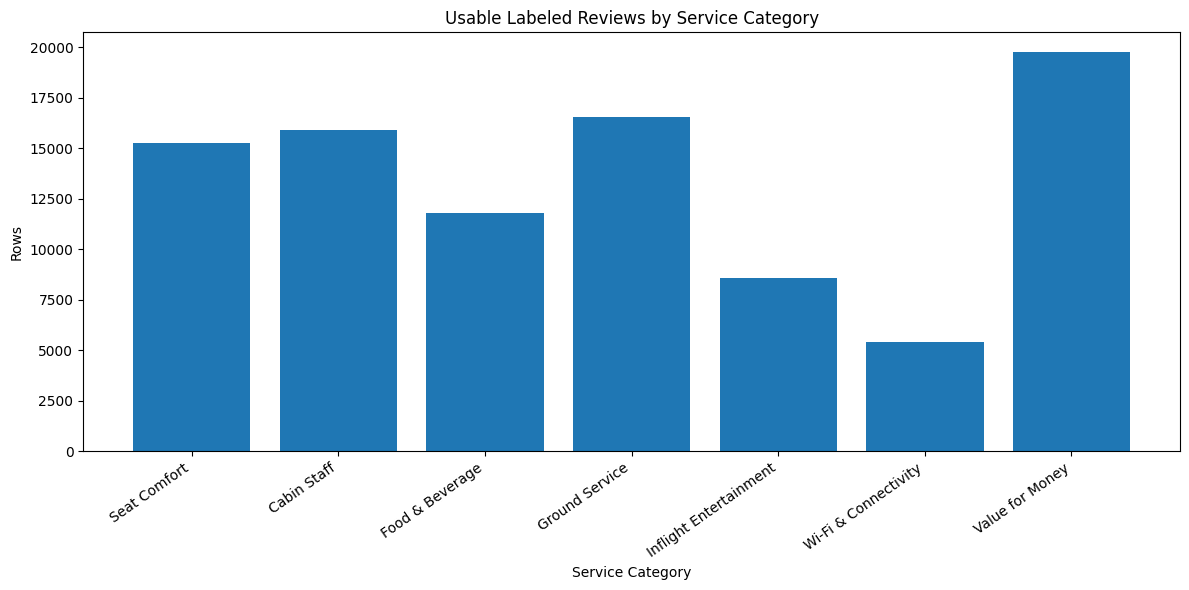

In [25]:
# Plot usable labeled reviews for each service category

plot_data = target_summary.copy()

# Create shorter labels for the graph
plot_data['Service Category'] = [
    'Seat Comfort',
    'Cabin Staff',
    'Food & Beverage',
    'Ground Service',
    'Inflight Entertainment',
    'Wi-Fi & Connectivity',
    'Value for Money'
]

plt.figure(figsize=(12, 6))

plt.bar(
    plot_data['Service Category'],
    plot_data['Usable Rows']
)

plt.title('Usable Labeled Reviews by Service Category')
plt.xlabel('Service Category')
plt.ylabel('Rows')

plt.xticks(
    rotation=35,
    ha='right'
)

plt.tight_layout()
plt.show()

## Text Cleaning

In [26]:

# Create a clean text column

stop_words = set(stopwords.words('english'))

# Keep important negation words
stop_words = stop_words - {'no', 'nor', 'not'}

lemmatizer = WordNetLemmatizer()


def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(
        r'http\S+|www\S+',
        ' ',
        text
    )

    # Keep letters and spaces only
    text = re.sub(
        r'[^a-z\s]',
        ' ',
        text
    )

    # Remove extra spaces
    text = re.sub(
        r'\s+',
        ' ',
        text
    ).strip()

    words = text.split()

    # Remove stop words and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
        and len(word) > 2
    ]

    return ' '.join(words)





**What this code does:**  
This function cleans the passenger review text before it is used for NLP modeling.

It:
- converts all text to lowercase;
- removes URLs;
- removes numbers, punctuation, and special characters;
- removes extra spaces;
- removes common stop words;
- keeps important negation words such as `no`, `nor`, and `not`;
- lemmatizes words to a simpler base form.

**Why this is used:**  
Passenger reviews contain many words and characters that do not help the model. Cleaning the text reduces noise and makes the reviews more consistent.

Keeping negation words is especially important because phrases such as “not comfortable" have a very different meaning from “comfortable.”

**Outcome:**  
The result is a cleaner version of each review that keeps the most useful words for NLP analysis and machine-learning modeling.

In [27]:
df['Clean_Review'] = df['Review'].apply(clean_text)

df[['Review', 'Clean_Review']].head()

,Review,Clean_Review
0,Moroni to Moheli. Turned out to be a pretty ...,moroni moheli turned pretty decent airline onl...
1,Moroni to Anjouan. It is a very small airline...,moroni anjouan small airline ticket advised tu...
2,Anjouan to Dzaoudzi. A very small airline an...,anjouan dzaoudzi small airline airline based c...
3,Please do a favor yourself and do not fly wi...,please favor not fly adria route munich pristi...
4,Do not book a flight with this airline! My fr...,not book flight airline friend returned sofia ...


>>This code applies the `clean_text()` function to every passenger review and saves the cleaned version in a new column called `Clean_Review`. The original review text is kept for reference, while the cleaned version is used for later NLP analysis such as word frequency, TF-IDF, and Logistic Regression.


In [28]:
#Check review length

df['Review_Length'] = df['Review'].astype(str).str.split().str.len()

print(df['Review_Length'].describe())


count    23051.000000
mean       130.639105
std         99.094140
min          2.000000
25%         64.000000
50%        101.000000
75%        164.000000
max        804.000000
Name: Review_Length, dtype: float64


>> Exploratory Text Analysis : After cleaning the review text, frequently occurring words and phrases were
examined to better understand the language used by passengers. Word clouds provide an intuitive visualization of common terms, while frequency tables and bigram analysis provide a more quantitative view of recurring language.

### WORD CLOUD

>>The below code selects only the reviews that were labeled as a **Value for Money problem** and combines their cleaned review text into one large text string. A word cloud is then created from that text. Words that appear more frequently are displayed in a larger size.The word cloud gives a quick visual summary of the language passengers commonly use when they are dissatisfied with Value for Money. It helps identify recurring words and themes before moving to more formal statistical and machine-learning analysis.

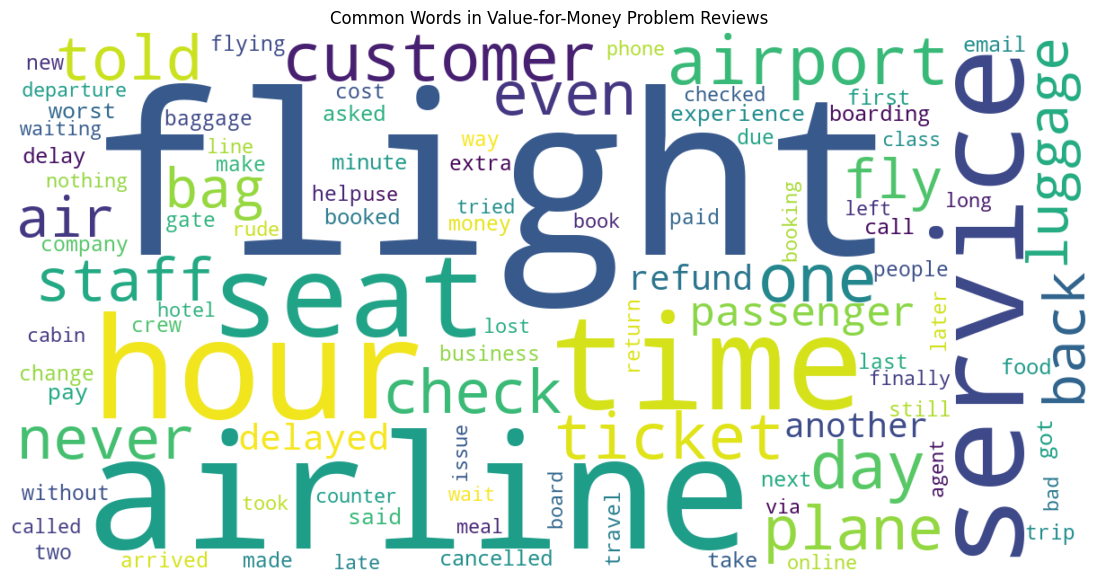

In [29]:
# Word cloud for Value-for-Money problem reviews

problem_text = ' '.join(
    df.loc[
        df['Value_For_Money_Problem'] == 1,
        'Clean_Review'
    ].dropna()
)

problem_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100,
    collocations=False
).generate(problem_text)

plt.figure(figsize=(14, 7))

plt.imshow(
    problem_wordcloud,
    interpolation='bilinear'
)

plt.axis('off')

plt.title(
    'Common Words in Value-for-Money Problem Reviews'
)

plt.show()

### NO-PROBLEM WORD CLOUD

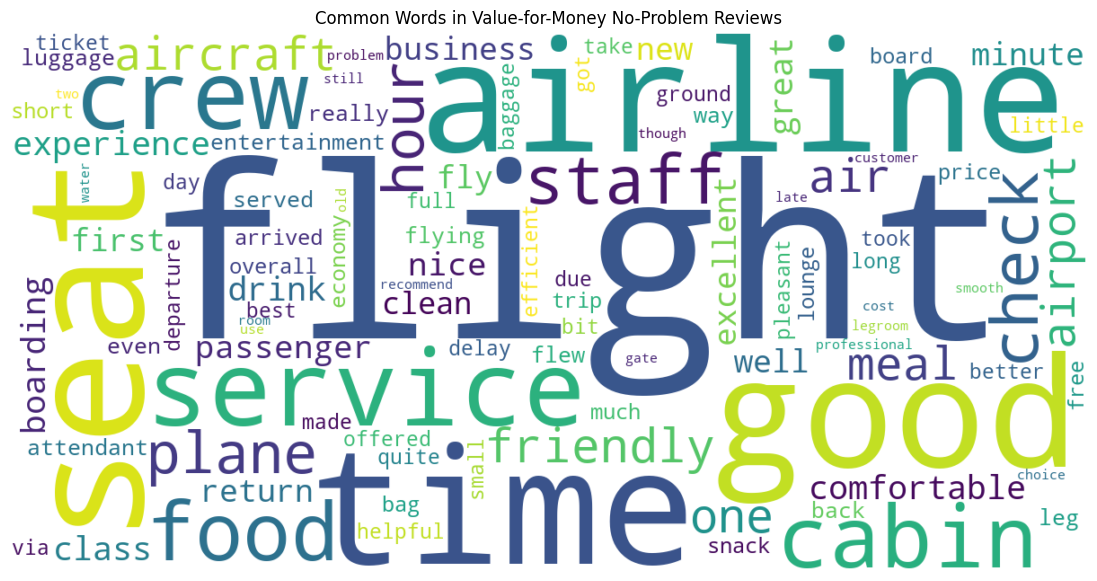

In [30]:
# Word cloud for Value-for-Money no-problem reviews

no_problem_text = ' '.join(
    df.loc[
        df['Value_For_Money_Problem'] == 0,
        'Clean_Review'
    ].dropna()
)

no_problem_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100,
    collocations=False
).generate(no_problem_text)

plt.figure(figsize=(14, 7))

plt.imshow(
    no_problem_wordcloud,
    interpolation='bilinear'
)

plt.axis('off')

plt.title(
    'Common Words in Value-for-Money No-Problem Reviews'
)

plt.show()

The word clouds provide an exploratory visualization of frequently occurring
terms in passenger reviews. The visualizations should not be interpreted as statistical evidence because
word size represents frequency rather than predictive importance. For this reason, quantitative term-frequency and machine-learning feature analysis are also included in the study.

### TOP 15 FREQUENT WORDS

In [31]:
# Function to identify frequently occurring words

def get_top_terms(text_series, n=15):

    vectorizer = CountVectorizer(
        max_features=5000
    )

    word_matrix = vectorizer.fit_transform(
        text_series.dropna()
    )

    frequencies = np.asarray(
        word_matrix.sum(axis=0)
    ).flatten()

    terms = vectorizer.get_feature_names_out()

    result = pd.DataFrame({
        'Term': terms,
        'Frequency': frequencies
    })

    return (
        result
        .sort_values(
            'Frequency',
            ascending=False
        )
        .head(n)
    )

In [32]:
value_problem_words = get_top_terms(
    df.loc[
        df['Value_For_Money_Problem'] == 1,
        'Clean_Review'
    ],
    n=15
)

value_problem_words

,Term,Frequency
1734,flight,29906
2957,not,17184
133,airline,12325
2091,hour,9334
4487,time,8233
3948,service,7368
3895,seat,6255
136,airport,5817
4961,would,5761
1121,customer,5708


>>This function counts how often each word appears in the cleaned review text and returns the most frequent words. `CountVectorizer` converts the text into a word-frequency matrix. The total frequency of each word is then calculated, sorted from highest to lowest, and the top 15 words are displayed.The word cloud gives a visual impression of common words, but this analysis provides exact frequency counts.This makes it easier to identify which words appear most often in Value-for-Money problem reviews.

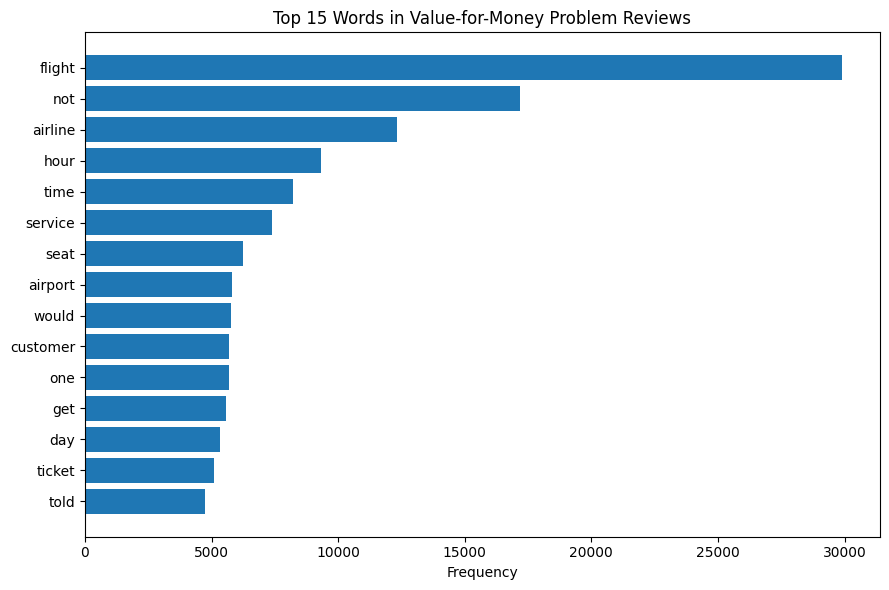

In [33]:
#Plot

plot_words = (
    value_problem_words
    .sort_values('Frequency')
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_words['Term'],
    plot_words['Frequency']
)

plt.xlabel('Frequency')

plt.title(
    'Top 15 Words in Value-for-Money Problem Reviews'
)

plt.tight_layout()
plt.show()

### BIGRAM ANALYSIS
Bigram analysis means looking at pairs of consecutive words instead of looking at single words one at a time.


In [34]:
# Function to find common two-word phrases

def get_top_bigrams(text_series, n=15):

    vectorizer = CountVectorizer(
        ngram_range=(2, 2),
        max_features=5000
    )

    bigram_matrix = vectorizer.fit_transform(
        text_series.dropna()
    )

    frequencies = np.asarray(
        bigram_matrix.sum(axis=0)
    ).flatten()

    terms = vectorizer.get_feature_names_out()

    result = pd.DataFrame({
        'Bigram': terms,
        'Frequency': frequencies
    })

    return (
        result
        .sort_values(
            'Frequency',
            ascending=False
        )
        .head(n)
    )

##Above function identifies the most common two-word combinations, called **bigrams**, in the cleaned passenger reviews. 
##`CountVectorizer` is set to `ngram_range=(2, 2)`, which means it looks at words in pairs instead of one word at a time. 
##The code then counts how often each two-word phrase appears and returns the 15 most frequent bigrams.

In [35]:
value_problem_bigrams = get_top_bigrams(
    df.loc[
        df['Value_For_Money_Problem'] == 1,
        'Clean_Review'
    ],
    n=15
)

value_problem_bigrams

,Bigram,Frequency
1067,customer service,3474
1681,flight delayed,1416
962,connecting flight,1028
684,business class,998
1652,flight cancelled,989
4903,worst airline,956
1004,could not,949
4956,would not,896
2910,never fly,890
3745,return flight,888


>> The result shows the most common two-word phrases in Value-for-Money problem reviews. 
In the current output, frequent bigrams include `customer service`, `flight delayed`, `connecting flight`, `flight cancelled`, `worst airline`, `could not`, and `would not`. These phrases help identify recurring patterns of dissatisfaction in passenger reviews.

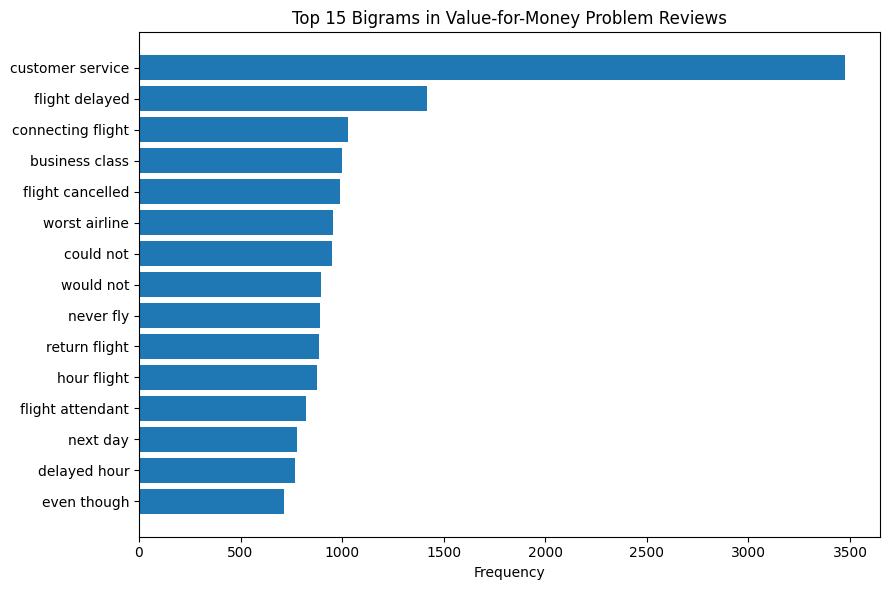

In [36]:
#Plot

plot_bigrams = (
    value_problem_bigrams
    .sort_values('Frequency')
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_bigrams['Bigram'],
    plot_bigrams['Frequency']
)

plt.xlabel('Frequency')

plt.title(
    'Top 15 Bigrams in Value-for-Money Problem Reviews'
)

plt.tight_layout()
plt.show()

>>For detailed exploratory text analysis, Value for Money is used as a representative example because it has the largest number of usable labeled reviews. The overall project, however, evaluates all seven airline service categories.

In [37]:
# Correlation between the seven service-problem target labels

target_corr = df[problem_columns].corr()

target_corr.round(2)

#This code calculates the correlation between the seven airline service-problem target variables.

,Seat_Comfort_Problem,Cabin_Staff_Problem,Food_Beverage_Problem,Ground_Service_Problem,Inflight_Entertainment_Problem,Wifi_Problem,Value_For_Money_Problem
Seat_Comfort_Problem,1.00,0.81,0.81,0.80,0.71,0.69,0.85
Cabin_Staff_Problem,0.81,1.00,0.80,0.75,0.64,0.62,0.80
Food_Beverage_Problem,0.81,0.80,1.00,0.76,0.75,0.73,0.84
Ground_Service_Problem,0.80,0.75,0.76,1.00,0.65,0.66,0.86
Inflight_Entertainment_Problem,0.71,0.64,0.75,0.65,1.00,0.81,0.69
Wifi_Problem,0.69,0.62,0.73,0.66,0.81,1.00,0.71
Value_For_Money_Problem,0.85,0.80,0.84,0.86,0.69,0.71,1.00


The `.corr()` function measures how strongly two service problems are related. Correlation values generally range from `-1` to `+1`.

- A value closer to `+1` means the two problems tend to occur together.
- A value near `0` means there is little relationship.
- A negative value means that when one problem occurs, the other tends to occur less often.

One passenger review can contain several service problems. For example, a passenger who reports poor Ground Service may also report poor Value for Money. The correlation matrix helps us understand whether certain airline service problems commonly appear together.

The result is a correlation table comparing all seven service categories. It helps identify groups of service problems that may be related.

Correlation shows an association between service problems, but it does not mean that one problem causes another.


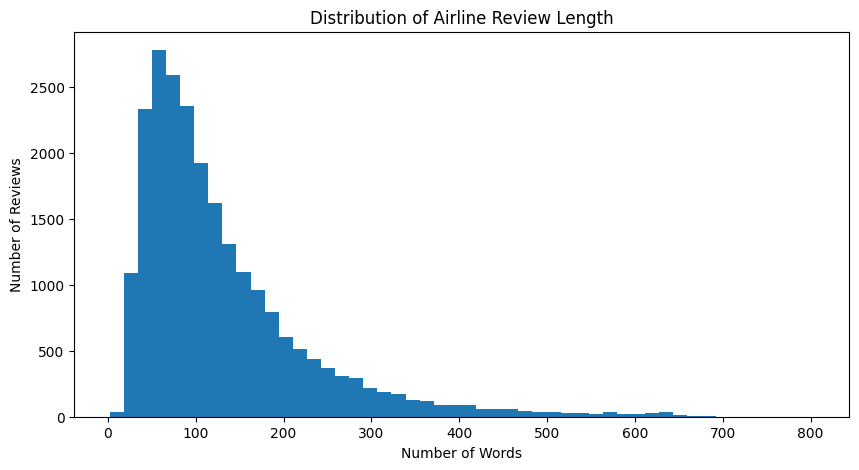

In [38]:
plt.figure(figsize=(10, 5))
plt.hist(df['Review_Length'], bins=50)
plt.title('Distribution of Airline Review Length')
plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')
plt.show()

>>The histogram shows that most airline reviews are relatively short to medium in length, with many reviews concentrated roughly below 200 words. The distribution is right-skewed, meaning there are fewer very long reviews, but some reviews extend to several hundred words.


In [39]:
#Define your seven target columns

target_columns = [
    'Seat_Comfort_Problem',
    'Cabin_Staff_Problem',
    'Food_Beverage_Problem',
    'Ground_Service_Problem',
    'Inflight_Entertainment_Problem',
    'Wifi_Problem',
    'Value_For_Money_Problem'
]

##This code creates a list containing the seven service-problem target variables used in the project.
##Instead of typing each target column repeatedly, the list allows the same code to loop through all seven service categories.

In [40]:
[col for col in df.columns if 'Problem' in col]

['Seat_Comfort_Problem',
 'Cabin_Staff_Problem',
 'Food_Beverage_Problem',
 'Ground_Service_Problem',
 'Inflight_Entertainment_Problem',
 'Wifi_Problem',
 'Value_For_Money_Problem']

### Multi-Label Modeling Strategy

This project represents a multi-label classification problem because a single
passenger review may be associated with more than one service problem.

For the TF-IDF and Logistic Regression baseline, the multi-label problem is
implemented using a binary relevance approach.

A separate binary classifier is trained for each service category. Therefore,
the same review may independently receive multiple service-problem labels.

For example, a review could be classified as:

- Seat Comfort Problem = 1
- Ground Service Problem = 1
- Cabin Staff Problem = 0

This approach allows multiple service issues to be associated with the same review.

## Logistic Regression Baseline

In [41]:
#Function to train one service category

def train_logistic_model(df, target_col):

    # Keep only rows where the target is known
    model_df = df[['Clean_Review', target_col]].dropna().copy()

    X = model_df['Clean_Review']
    y = model_df[target_col].astype(int)

    print("\n")
    print("=" * 60)
    print("TARGET:", target_col)
    print("=" * 60)

    print("Usable rows:", len(model_df))
    print("\nClass distribution:")
    print(y.value_counts())

    # 80/20 stratified split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    # TF-IDF
    tfidf = TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=3,
        max_df=0.95,
        sublinear_tf=True
    )

    X_train_tfidf = tfidf.fit_transform(X_train)
    X_test_tfidf = tfidf.transform(X_test)

    # Logistic Regression
    model = LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    )

    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    print("\nAccuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))

    return {
        'target': target_col,
        'model': model,
        'vectorizer': tfidf,
        'X_test': X_test,
        'y_test': y_test,
        'predictions': predictions,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

The above code (function) trains one Logistic Regression model for a selected service category. It first removes rows where the target label is missing, then splits the cleaned review text into training and testing data. TF-IDF converts the review text into numerical features using both single words and two-word phrases, and Logistic Regression learns to classify each review as a service problem or no problem. The model also uses balanced class weights to reduce the effect of class imbalance. Finally, it evaluates the model using accuracy, precision, recall, F1 score, and a classification report, and stores the trained model and results for later comparison.

In [42]:
#Train all seven Logistic Regression models


logistic_results = {}

for target in target_columns:
    logistic_results[target] = train_logistic_model(df, target)



TARGET: Seat_Comfort_Problem
Usable rows: 15247

Class distribution:
Seat_Comfort_Problem
1    9201
0    6046
Name: count, dtype: int64

Accuracy : 0.8944
Precision: 0.9072
Recall   : 0.9191
F1 Score : 0.9131

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.87      1209
           1       0.91      0.92      0.91      1841

    accuracy                           0.89      3050
   macro avg       0.89      0.89      0.89      3050
weighted avg       0.89      0.89      0.89      3050



TARGET: Cabin_Staff_Problem
Usable rows: 15927

Class distribution:
Cabin_Staff_Problem
1    8328
0    7599
Name: count, dtype: int64

Accuracy : 0.8635
Precision: 0.8406
Recall   : 0.9118
F1 Score : 0.8747

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.81      0.85      1520
           1       0.84      0.91      0.87      1666

    accuracy                           0.

In [43]:
#Create a results table

logistic_summary = pd.DataFrame([
    {
        'Target': target,
        'Accuracy': result['accuracy'],
        'Precision': result['precision'],
        'Recall': result['recall'],
        'F1 Score': result['f1']
    }

    for target, result in logistic_results.items()
])

logistic_summary

,Target,Accuracy,Precision,Recall,F1 Score
0,Seat_Comfort_Problem,0.894426,0.907239,0.919066,0.913114
1,Cabin_Staff_Problem,0.863465,0.840620,0.911765,0.874748
2,Food_Beverage_Problem,0.890063,0.913194,0.906897,0.910035
3,Ground_Service_Problem,0.916415,0.948148,0.925441,0.936657
4,Inflight_Entertainment_Problem,0.838560,0.901612,0.867755,0.884359
5,Wifi_Problem,0.896869,0.953303,0.921806,0.937290
6,Value_For_Money_Problem,0.930144,0.951229,0.938370,0.944756


>>This table combines the results from all seven Logistic Regression models so they can be compared easily. It shows Accuracy, Precision, Recall, and F1 Score for each service category. 

**F1 score** is a commonly used evaluation metric for classification models because it combines Precision and Recall into a single measure. It is especially useful when both false positives and false negatives are important, or when the classes are not perfectly balanced. A high F1 score means the model is doing a good job of correctly identifying positive cases while also avoiding too many incorrect positive predictions. Because it balances these two aspects of model performance, F1 score is often used to compare classification models more fairly than accuracy alone.

In [44]:
#Sort by F1 score:

logistic_summary.sort_values(
    by='F1 Score',
    ascending=False
)

,Target,Accuracy,Precision,Recall,F1 Score
6,Value_For_Money_Problem,0.930144,0.951229,0.938370,0.944756
5,Wifi_Problem,0.896869,0.953303,0.921806,0.937290
3,Ground_Service_Problem,0.916415,0.948148,0.925441,0.936657
0,Seat_Comfort_Problem,0.894426,0.907239,0.919066,0.913114
2,Food_Beverage_Problem,0.890063,0.913194,0.906897,0.910035
4,Inflight_Entertainment_Problem,0.838560,0.901612,0.867755,0.884359
1,Cabin_Staff_Problem,0.863465,0.840620,0.911765,0.874748


>>This table ranks the seven Logistic Regression models from highest to lowest F1 score.
>>Value for Money performed best with an F1 score of about 0.94, followed closely by Wi-Fi and Ground Service. Seat Comfort and Food & Beverage also showed strong performance, while Inflight Entertainment and Cabin Staff had the lowest F1 scores among the seven categories. This ranking helps identify which service problems are easier or harder to predict from passenger review text.

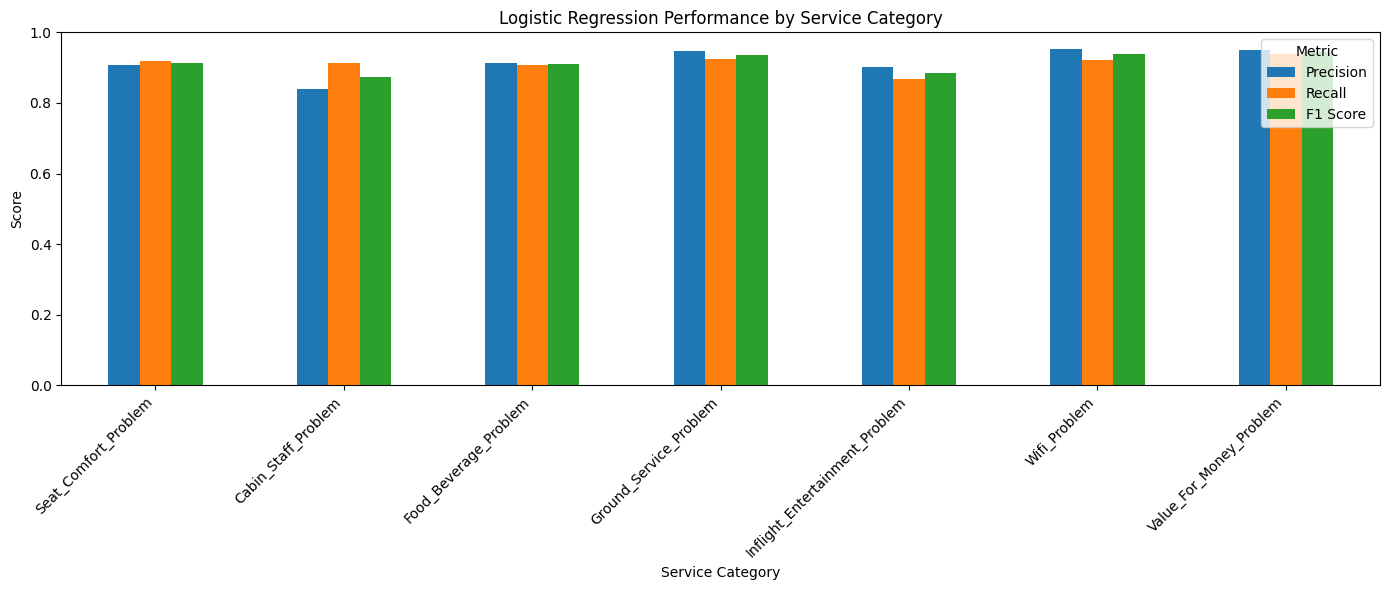

In [45]:
#Graph model performance

plot_df = logistic_summary.set_index('Target')[
    ['Precision', 'Recall', 'F1 Score']
]

plot_df.plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Logistic Regression Performance by Service Category')
plt.ylabel('Score')
plt.xlabel('Service Category')
plt.ylim(0, 1)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

>>This graph compares Precision, Recall, and F1 Score across all seven Logistic Regression models. It provides a quick visual way to compare how well each service category is being predicted. Most categories show strong and fairly balanced performance, while Cabin Staff and Inflight Entertainment are slightly lower than the others. Value for Money, Ground Service, and Wi-Fi show some of the strongest overall results. The graph makes it easier to compare model performance across categories than looking at the numerical table alone.

### Confusion Matrices
A confusion matrix compares the model’s predicted labels with the actual labels and shows how many reviews were correctly or incorrectly classified as Problem or No Problem. It is useful because it gives more detail than accuracy alone and helps identify false positives and false negatives.


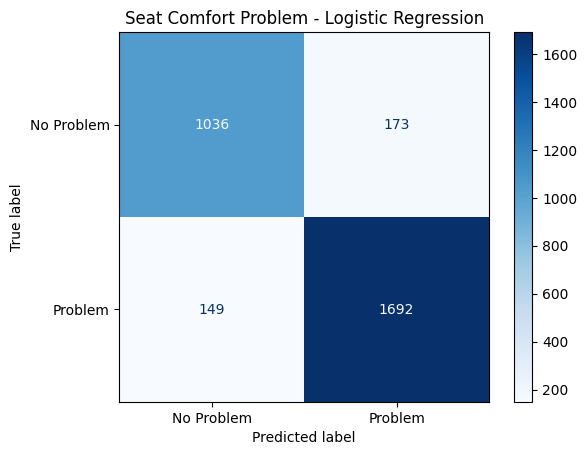

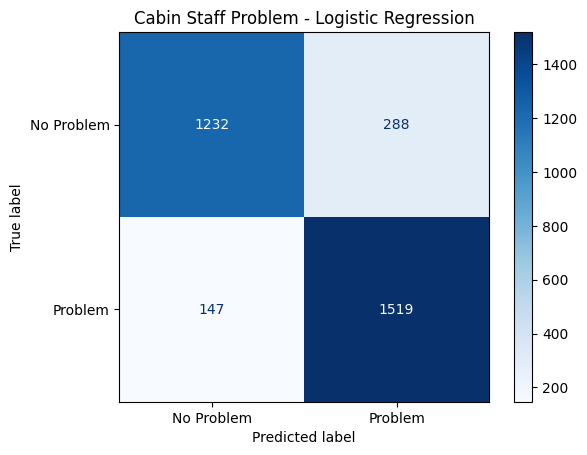

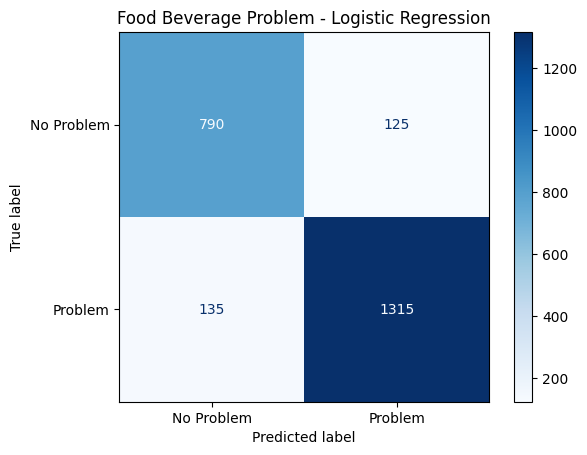

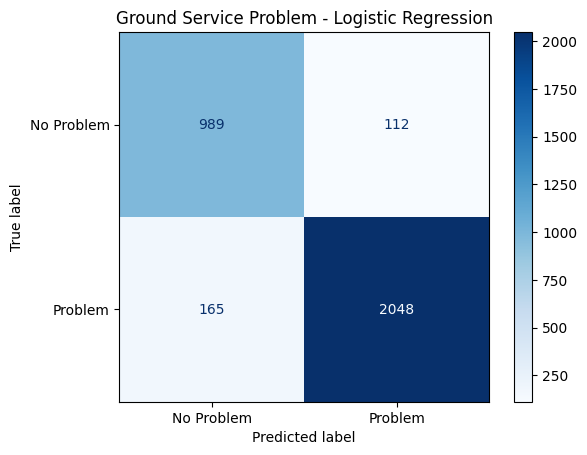

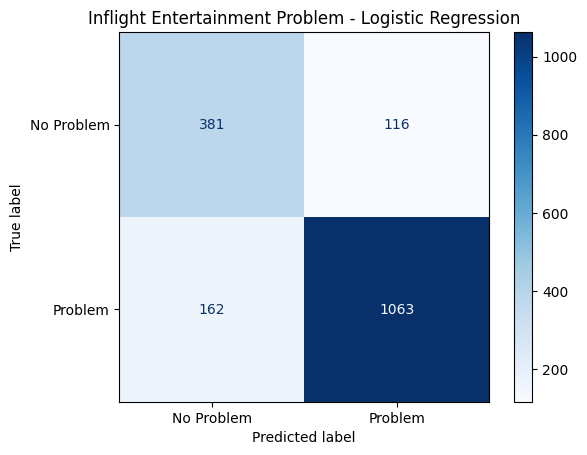

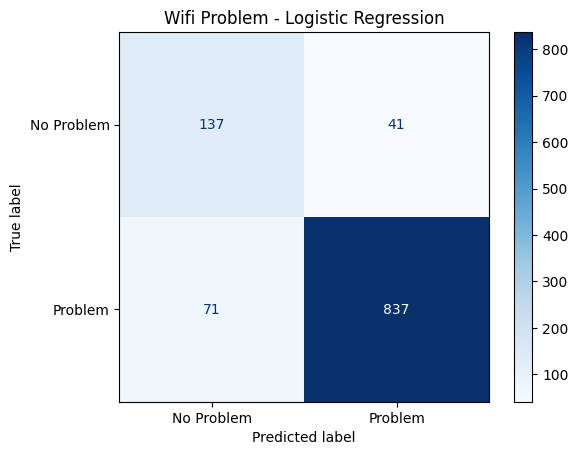

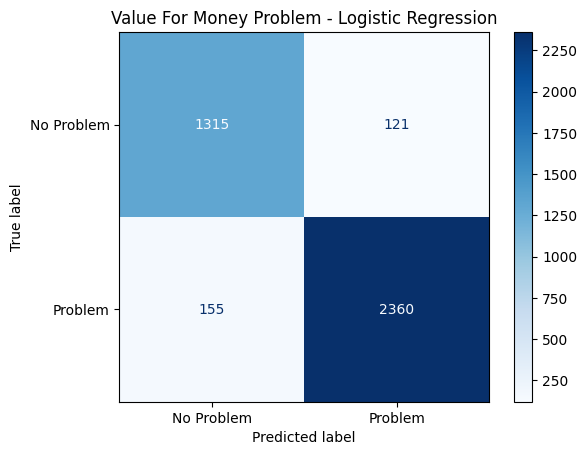

In [46]:
#Plot confusion matrix for every target

for target, result in logistic_results.items():

    cm = confusion_matrix(
        result['y_test'],
        result['predictions']
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Problem', 'Problem']
    )

    disp.plot(cmap='Blues')

    plt.title(
        target.replace('_', ' ') +
        ' - Logistic Regression'
    )

    plt.show()

>>This output shows how well the Logistic Regression models classified Problem and No Problem reviews for each service category.
For Seat Comfort, the model correctly identified 1,036 no-problem reviews and 1,692 problem reviews. It made 173 false positive predictions and missed 149 actual problems. This indicates strong performance for both classes.
>>
>>For Cabin Staff, the model correctly classified 1,232 no-problem reviews and 1,519 problem reviews. It produced 288 false positives and 147 false negatives. This shows that the model detects most Cabin Staff problems well, but it incorrectly labels some no-problem reviews as problems more often than the Seat Comfort model.
>>
>> Food & Beverage, Ground Service, and Value for Money show strong performance because most predictions fall along the diagonal, meaning the predicted labels match the actual labels.
>>
>>Inflight Entertainment has more classification errors compared with the stronger models. The Wi-Fi model correctly identifies most problem reviews, but the much smaller number of no-problem cases shows the effect of class imbalance. 

### Most Important Words

In [47]:
### Extract important words for each category

def show_important_words(result, top_n=15):

    model = result['model']
    vectorizer = result['vectorizer']

    feature_names = np.array(
        vectorizer.get_feature_names_out()
    )

    coefficients = model.coef_[0]

    strongest_problem_words = feature_names[
        np.argsort(coefficients)[-top_n:]
    ][::-1]

    strongest_no_problem_words = feature_names[
        np.argsort(coefficients)[:top_n]
    ]

    print("Words associated with SERVICE PROBLEMS:")
    print(strongest_problem_words)

    print("\nWords associated with NO SERVICE PROBLEM:")
    print(strongest_no_problem_words)

In [48]:
show_important_words(
    logistic_results['Seat_Comfort_Problem']
)

Words associated with SERVICE PROBLEMS:
['uncomfortable' 'worst' 'not' 'terrible' 'never' 'horrible' 'cramped'
 'rude' 'hour' 'seat' 'pay' 'poor' 'not comfortable' 'old' 'jetstar']

Words associated with NO SERVICE PROBLEM:
['good' 'comfortable' 'great' 'excellent' 'nice' 'thank' 'clean'
 'friendly' 'crew' 'pleasant' 'smooth' 'helpful' 'seat comfortable' 'easy'
 'amazing']


>>This analysis is included to make the Logistic Regression model more interpretable. The model performance metrics show how accurate the predictions are, while the coefficient analysis helps explain which words and phrases influence those predictions. This is useful in an NLP project because it connects the model results back to actual passenger language and helps identify common expressions associated with service problems and positive experiences.

In [49]:
for target in target_columns:

    print("\n")
    print("=" * 60)
    print(target)
    print("=" * 60)

    show_important_words(
        logistic_results[target],
        top_n=10
    )



Seat_Comfort_Problem
Words associated with SERVICE PROBLEMS:
['uncomfortable' 'worst' 'not' 'terrible' 'never' 'horrible' 'cramped'
 'rude' 'hour' 'seat']

Words associated with NO SERVICE PROBLEM:
['good' 'comfortable' 'great' 'excellent' 'nice' 'thank' 'clean'
 'friendly' 'crew' 'pleasant']


Cabin_Staff_Problem
Words associated with SERVICE PROBLEMS:
['not' 'rude' 'worst' 'never' 'terrible' 'poor' 'horrible' 'ever' 'even'
 'avoid']

Words associated with NO SERVICE PROBLEM:
['good' 'great' 'excellent' 'nice' 'friendly' 'thank' 'helpful'
 'comfortable' 'pleasant' 'best']


Food_Beverage_Problem
Words associated with SERVICE PROBLEMS:
['poor' 'worst' 'not' 'never' 'terrible' 'water' 'delayed' 'hour' 'pay'
 'rude']

Words associated with NO SERVICE PROBLEM:
['good' 'great' 'excellent' 'nice' 'thank' 'comfortable' 'friendly'
 'professional' 'impressed' 'tasty']


Ground_Service_Problem
Words associated with SERVICE PROBLEMS:
['worst' 'not' 'rude' 'never' 'terrible' 'hour' 'delayed' 'p

## Results Interpretation

The TF-IDF and Logistic Regression baseline produced strong classification
performance across all seven airline service categories.

The highest F1 score was achieved for Value for Money, followed closely by
Wi-Fi & Connectivity and Ground Service. Seat Comfort and Food & Beverage
also showed strong performance, while Cabin Staff Service and Inflight
Entertainment were relatively more difficult to classify.

These results suggest that passenger review text contains meaningful language
patterns that can be used to identify specific service-related problems.

The feature-coefficient analysis also showed clear differences between
problem and no-problem reviews. Words such as "worst," "rude," "terrible,"
"uncomfortable," "cramped," and "not" were frequently associated with
service-problem predictions, while words such as "good," "comfortable,"
"excellent," "friendly," and "helpful" were more strongly associated with
no-problem reviews.

Although Wi-Fi achieved a high F1 score for the problem class, its results
should be interpreted carefully because this category contains relatively few
usable observations and a highly imbalanced target distribution. Therefore,
class-specific metrics and the confusion matrix are important in addition to
overall performance measures.

#### Let’s Revisit the Research Questions: Were They Addressed?


1. Can passenger review text be used to identify specific airline service problems?
 After cleaning the review text and converting it to TF-IDF features, the models were able to classify seven different service-problem categories with strong performance. This shows that the language in passenger reviews contains enough information to identify specific airline service issues.

2. How accurately can TF-IDF and Logistic Regression classify the seven service categories?
Project answer this with Accuracy, Precision, Recall, F1 Score, Classification Reports, and Confusion Matrices. 

3. Which airline service categories are easier or more difficult to predict?
 Comparison table and F1-score ranking answer this directly. Value for Money, Ground Service, and Wi-Fi produced some of the highest F1 scores, while Cabin Staff and Inflight Entertainment were relatively more difficult. 

4. What words and phrases are most strongly associated with service problems and positive experiences?
 Word-frequency analysis, bigram analysis, word cloud, and especially the Logistic Regression coefficient analysis address this question. Terms such as “worst,” “rude,” “terrible,” “uncomfortable,” and “cramped” are associated with service problems, while terms such as “good,” “excellent,” “comfortable,” “friendly,” and “helpful” are associated with no-problem reviews. Bigrams such as “customer service,” “flight delayed,” and “flight cancelled” provide additional context.

5. How does class imbalance affect model performance across service categories?
Some categories have many more problem reviews than no-problem reviews, especially Wi-Fi, where about 84% of usable reviews are problems. To reduce this imbalance, the Logistic Regression model uses class_weight='balanced'. Precision, Recall, F1 Score, and confusion matrices are also used instead of relying only on accuracy. This helps give a fairer view of model performance across the different service categories.

## Limitations

One limitation of this project is that the service-problem labels were created from passenger rating scores rather than manually labeled review text, so the labels may not always perfectly match the wording of the reviews. Ratings of 3 were treated as neutral and excluded, reducing the number of usable observations. Some categories, especially Wi-Fi and Inflight Entertainment, also contained substantial missing data and class imbalance. In addition, TF-IDF with Logistic Regression can identify important words and phrases but does not fully capture word order, sentence structure, or deeper context. Because a single review may discuss several service issues at the same time, some categories may overlap, making classification more difficult.

## Additional Validation: Text vs. Overall Rating

This analysis tests whether review text provides more information about service problems than the overall passenger rating alone. 
For each service category, both models use the same observations and training/test split. Reviews without an overall rating are excluded from this comparison, so results may differ from the earlier text-only analysis. 
Five-fold stratified cross-validation is used for parameter selection within the training set. TF-IDF is fitted separately
inside each fold to avoid vocabulary leakage. 
Models are selected using macro F1, which gives equal weight to the problem and no-problem classes.

In [51]:



def evaluate_classifier(model, X_test, y_test):
    predictions = model.predict(X_test)

    # Probability that a review belongs to class 1: Problem
    problem_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_test)[:, problem_index]

    scores = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Problem Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Problem Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Problem F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "No-Problem F1": f1_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(
            y_test, probabilities
        )
    }

    return scores, predictions, probabilities

In [55]:
#train and compare all seven categories

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

validation_results = {}
comparison_rows = []

for target in target_columns:
    print(f"\nEvaluating: {target}")

    # Use identical eligible rows for both models.
    eligible = df[
        ["Clean_Review", "Overall_Rating", target]
    ].copy()

    eligible["Overall_Rating"] = pd.to_numeric(
        eligible["Overall_Rating"], errors="coerce"
    )

    # Invalid or zero ratings are not treated as real scores.
    eligible.loc[
        ~eligible["Overall_Rating"].between(1, 10),
        "Overall_Rating"
    ] = np.nan

    eligible = eligible.dropna(
        subset=["Clean_Review", "Overall_Rating", target]
    )

    eligible = eligible[
        eligible["Clean_Review"].astype(str).str.strip().ne("")
    ].reset_index(drop=True)

    y = eligible[target].astype(int)

    train_idx, test_idx = train_test_split(
        np.arange(len(eligible)),
        test_size=0.20,
        stratify=y,
        random_state=42
    )

    train_data = eligible.iloc[train_idx]
    test_data = eligible.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    if y_train.value_counts().min() < 5:
        raise ValueError(
            f"{target}: insufficient minority-class training "
            "observations for five-fold cross-validation."
        )

    # Reuse exactly the same CV folds for both models.
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
    folds = list(cv.split(train_data, y_train))

    text_pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            min_df=3,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

    rating_pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

    configurations = {
        "Text model": (
            text_pipeline,
            {
                "tfidf__ngram_range": [(1, 1), (1, 2)],
                "model__C": [0.1, 1.0, 10.0],
                "model__class_weight": [None, "balanced"]
            },
            train_data["Clean_Review"],
            test_data["Clean_Review"]
        ),
        "Overall-rating baseline": (
            rating_pipeline,
            {
                "model__C": [0.1, 1.0, 10.0],
                "model__class_weight": [None, "balanced"]
            },
            train_data[["Overall_Rating"]],
            test_data[["Overall_Rating"]]
        )
    }

    validation_results[target] = {}

    for name, (pipeline, parameters, X_train, X_test) in (
        configurations.items()
    ):
        search = GridSearchCV(
            estimator=pipeline,
            param_grid=parameters,
            scoring={
                "macro_f1": "f1_macro",
                "roc_auc": "roc_auc"
            },
            refit="macro_f1",
            cv=folds,
            n_jobs=2,
            error_score="raise"
        )

        search.fit(X_train, y_train)

        scores, predictions, probabilities = evaluate_classifier(
            search.best_estimator_, X_test, y_test
        )

        best_index = search.best_index_

        comparison_rows.append({
            "Target": target,
            "Model": name,
            "Train Rows": len(train_data),
            "Test Rows": len(test_data),
            "Test Problem Rate": y_test.mean(),
            "CV Macro F1": search.best_score_,
            "CV Macro F1 SD": search.cv_results_[
                "std_test_macro_f1"
            ][best_index],
            "CV ROC-AUC": search.cv_results_[
                "mean_test_roc_auc"
            ][best_index],
            **scores
        })

        validation_results[target][name] = {
            "search": search,
            "y_test": y_test,
            "predictions": predictions,
            "probabilities": probabilities
        }

        print(f"\n{name}")
        print("Best parameters:", search.best_params_)
        print(classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["No Problem", "Problem"],
            zero_division=0
        ))

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df.round(4))


Evaluating: Seat_Comfort_Problem

Text model
Best parameters: {'model__C': 1.0, 'model__class_weight': None, 'tfidf__ngram_range': (1, 2)}
              precision    recall  f1-score   support

  No Problem       0.90      0.81      0.85      1207
     Problem       0.88      0.94      0.91      1825

    accuracy                           0.89      3032
   macro avg       0.89      0.87      0.88      3032
weighted avg       0.89      0.89      0.89      3032


Overall-rating baseline
Best parameters: {'model__C': 0.1, 'model__class_weight': None}
              precision    recall  f1-score   support

  No Problem       0.80      0.57      0.67      1207
     Problem       0.76      0.91      0.83      1825

    accuracy                           0.77      3032
   macro avg       0.78      0.74      0.75      3032
weighted avg       0.78      0.77      0.76      3032


Evaluating: Cabin_Staff_Problem

Text model
Best parameters: {'model__C': 1.0, 'model__class_weight': None, 'tfidf__

,Target,Model,Train Rows,Test Rows,Test Problem Rate,CV Macro F1,CV Macro F1 SD,CV ROC-AUC,Accuracy,Problem Precision,Problem Recall,Problem F1,No-Problem F1,Macro F1,ROC-AUC,Average Precision
0,Seat_Comfort_Problem,Text model,12127,3032,0.6019,0.8889,0.0081,0.9419,0.8875,0.8821,0.9386,0.9095,0.8515,0.8805,0.9450,0.9531
1,Seat_Comfort_Problem,Overall-rating baseline,12127,3032,0.6019,0.7483,0.0079,0.7453,0.7731,0.7616,0.9068,0.8279,0.6670,0.7475,0.7441,0.7462
2,Cabin_Staff_Problem,Text model,12634,3159,0.5195,0.8696,0.0069,0.9237,0.8712,0.8462,0.9190,0.8811,0.8594,0.8703,0.9201,0.8966
3,Cabin_Staff_Problem,Overall-rating baseline,12634,3159,0.5195,0.7399,0.0118,0.7667,0.7373,0.7012,0.8611,0.7730,0.6882,0.7306,0.7585,0.6913
4,Food_Beverage_Problem,Text model,9390,2348,0.6107,0.8794,0.0064,0.9362,0.8884,0.9104,0.9066,0.9085,0.8571,0.8828,0.9413,0.9554
5,Food_Beverage_Problem,Overall-rating baseline,9390,2348,0.6107,0.7368,0.0102,0.7107,0.7632,0.7546,0.9073,0.8239,0.6385,0.7312,0.7041,0.7217
6,Ground_Service_Problem,Text model,13254,3314,0.6678,0.9034,0.0036,0.9607,0.9200,0.9497,0.9295,0.9395,0.8822,0.9108,0.9648,0.9798
7,Ground_Service_Problem,Overall-rating baseline,13254,3314,0.6678,0.7834,0.0106,0.7563,0.8358,0.8276,0.9526,0.8857,0.7088,0.7972,0.7746,0.8160
8,Inflight_Entertainment_Problem,Text model,6829,1708,0.7096,0.8075,0.0112,0.8902,0.8460,0.9059,0.8738,0.8895,0.7459,0.8177,0.8912,0.9428
9,Inflight_Entertainment_Problem,Overall-rating baseline,6829,1708,0.7096,0.6808,0.0046,0.6597,0.7717,0.7907,0.9224,0.8515,0.5063,0.6789,0.6600,0.7800


In [56]:
#showing whether text outperforms the baseline

performance_comparison = comparison_df.pivot(
    index="Target",
    columns="Model",
    values=["Macro F1", "ROC-AUC"]
)

display(performance_comparison.round(4))

text_scores = (
    comparison_df[comparison_df["Model"] == "Text model"]
    .set_index("Target")
)

baseline_scores = (
    comparison_df[
        comparison_df["Model"] == "Overall-rating baseline"
    ]
    .set_index("Target")
)

text_advantage = pd.DataFrame({
    "Text Minus Baseline: Macro F1":
        text_scores["Macro F1"] - baseline_scores["Macro F1"],
    "Text Minus Baseline: ROC-AUC":
        text_scores["ROC-AUC"] - baseline_scores["ROC-AUC"]
})

display(text_advantage.round(4))

Macro F1             \
Model                          Overall-rating baseline Text model   
Target                                                              
Cabin_Staff_Problem                             0.7306     0.8703   
Food_Beverage_Problem                           0.7312     0.8828   
Ground_Service_Problem                          0.7972     0.9108   
Inflight_Entertainment_Problem                  0.6789     0.8177   
Seat_Comfort_Problem                            0.7475     0.8805   
Value_For_Money_Problem                         0.8116     0.9247   
Wifi_Problem                                    0.6606     0.8169   

                                               ROC-AUC             
Model                          Overall-rating baseline Text model  
Target                                                             
Cabin_Staff_Problem                             0.7585     0.9201  
Food_Beverage_Problem                           0.7041     0.9413  
Ground_Service_Problem                          0.7746     0.9648  
Inflight_Entertainment_Problem                  0.6600     0.8912  
Seat_Comfort_Problem                            0.7441     0.9450  
Value_For_Money_Problem                         0.7858     0.9712  
Wifi_Problem                                    0.6413     0.8946

,Text Minus Baseline: Macro F1,Text Minus Baseline: ROC-AUC
Target,,
Seat_Comfort_Problem,0.1331,0.2009
Cabin_Staff_Problem,0.1397,0.1616
Food_Beverage_Problem,0.1516,0.2371
Ground_Service_Problem,0.1136,0.1902
Inflight_Entertainment_Problem,0.1388,0.2313
Wifi_Problem,0.1563,0.2533
Value_For_Money_Problem,0.1131,0.1854


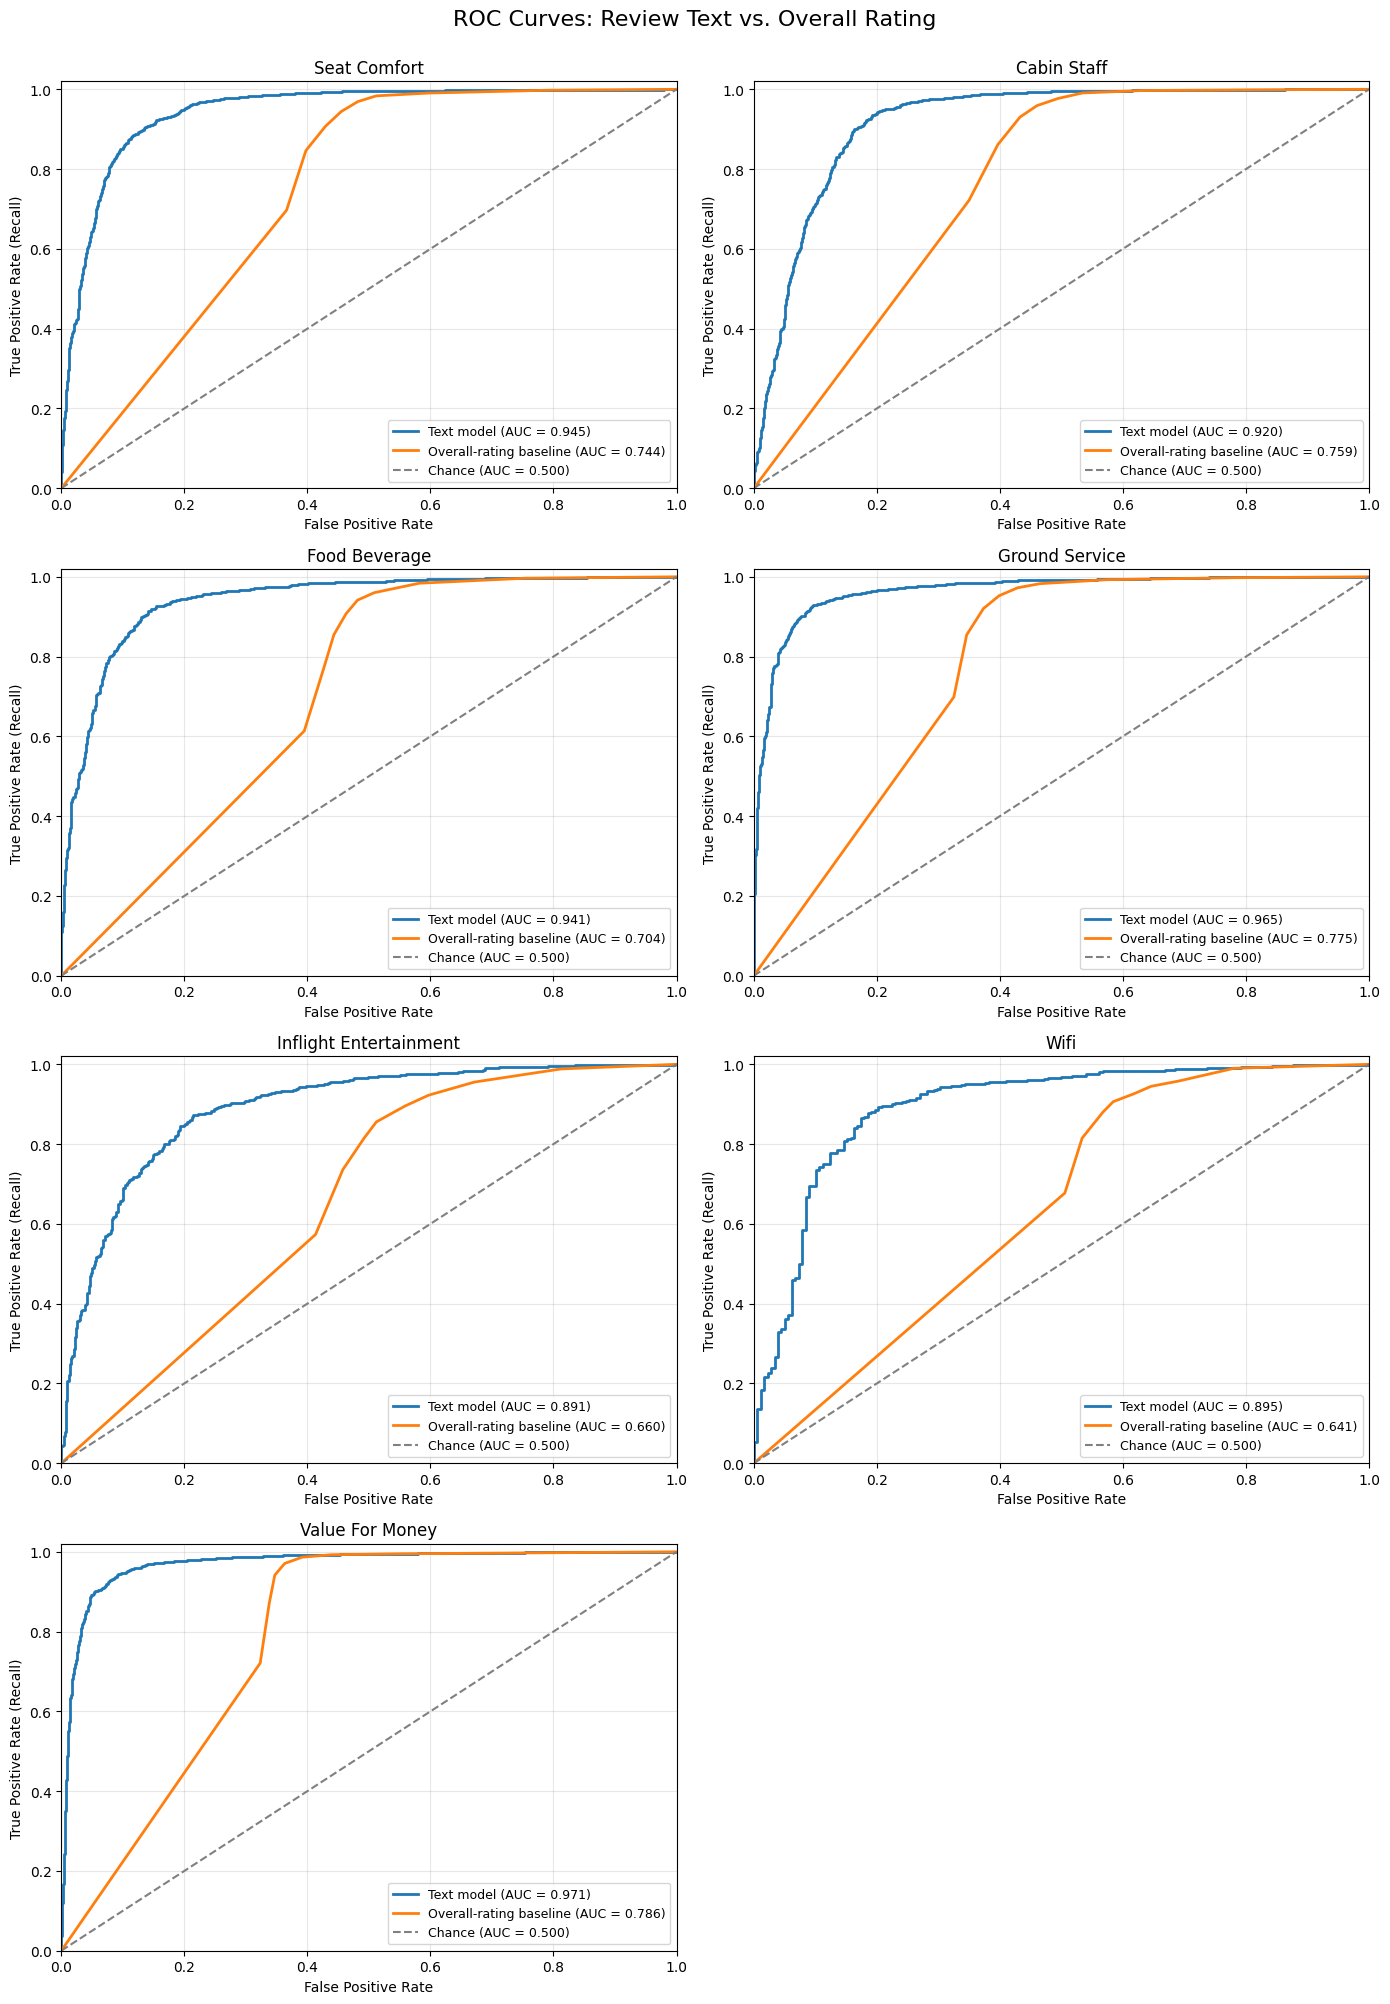

In [57]:

from sklearn.metrics import roc_curve, roc_auc_score

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes = axes.flatten()

for ax, target in zip(axes, target_columns):

    for model_name, color in [
        ("Text model", "tab:blue"),
        ("Overall-rating baseline", "tab:orange")
    ]:
        result = validation_results[target][model_name]

        y_true = result["y_test"]
        probabilities = result["probabilities"]

        fpr, tpr, _ = roc_curve(y_true, probabilities)
        auc_score = roc_auc_score(y_true, probabilities)

        ax.plot(
            fpr,
            tpr,
            color=color,
            linewidth=2,
            label=f"{model_name} (AUC = {auc_score:.3f})"
        )

    # Reference line for a classifier with no discrimination
    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        label="Chance (AUC = 0.500)"
    )

    title = target.replace("_Problem", "").replace("_", " ")

    ax.set_title(title)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate (Recall)")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right", fontsize=9)

# Hide the unused eighth panel
for ax in axes[len(target_columns):]:
    ax.set_visible(False)

fig.suptitle(
    "ROC Curves: Review Text vs. Overall Rating",
    fontsize=16,
    y=1.00
)

plt.tight_layout()
plt.show()

>>Interpreting the Validation Results

>>
>>The tuned text classifiers outperformed the overall-rating-only baseline across all seven service categories. Improvements in macro F1 ranged from 0.1131 to 0.1563, while improvements in ROC-AUC ranged from 0.1616 to 0.2533. Value for Money achieved the highest text-model macro F1 of 0.9247 and ROC-AUC of 0.9712, followed by strong results for Ground Service. Wi-Fi showed the largest improvement over the baseline, with macro F1 increasing from 0.6606 to 0.8169 and ROC-AUC increasing from 0.6413 to 0.8946. The ROC curves also showed that the text models generally achieved higher true-positive rates at comparable false-positive rates. These results suggest that review text provides useful predictive information beyond the overall numerical rating. However, they do not prove that the models learned service-specific language, because text may capture more detailed overall sentiment. Further evaluation could compare reviews with identical overall ratings but different service labels or use manually annotated service-specific passages. Wi-Fi results require particular caution because many ratings are missing and the observed labels are imbalanced, so performance may not generalize to unrated reviews. Finally, the new macro F1 scores should not be directly compared with the earlier problem-class F1 scores because they measure different aspects of performance and use different eligible observations.

## Conclusion

This project showed that passenger review text can be used effectively to identify specific airline service problems using NLP. After cleaning the reviews and converting service ratings into binary problem labels, TF-IDF and Logistic Regression models were built for seven service categories. The models produced strong results across most categories, with especially good performance for Value for Money, Ground Service, Wi-Fi, Seat Comfort, and Food & Beverage. The analysis also identified meaningful words and phrases associated with both negative and positive passenger experiences. Overall, the results demonstrate that a traditional NLP approach can provide a useful and interpretable baseline for automatically organizing airline customer feedback and identifying recurring service concerns.


## Future Work

The current project establishes TF-IDF with Logistic Regression as a strong
and interpretable NLP baseline. Future work can extend the analysis by
comparing this baseline with more advanced deep-learning and transformer-based
approaches.

Possible future models include:

- Bidirectional Long Short-Term Memory (BiLSTM) networks, which can capture
  word order and context from both directions in a review;

- Convolutional Neural Network (CNN) models for identifying important local
  word and phrase patterns;

- hybrid CNN-BiLSTM models that combine local feature extraction with
  sequential context;

- BiLSTM with attention mechanisms, which can place greater emphasis on the
  most informative parts of a passenger review;

- GRU or BiGRU networks as computationally simpler alternatives to LSTM-based
  models;

- transformer-based models such as BERT or DistilBERT, which can capture
  richer contextual relationships between words.

Future research could also evaluate airline-specific patterns, changes in
passenger concerns over time, traveler type, seat type, and other available
features. 

